# IBD012 — Análise exploratória em SQLite
## Saúde da mulher na África Subsaariana

**Objetivo:** transformar um recorte dos dados do TP em um banco relacional SQLite e explorá-lo com SQL.

**Grupo:** Henrique Lima Gusmão (2025014508); Felipe Pires Franco (2025051411);
Izabella Galdino Correia (2025096601); Alice Lina Oliveira da Silva (2025106933).

O exercício segue três passos: ler os dados, criar quatro tabelas relacionadas e responder perguntas exploratórias.
Execute as células em ordem, com o diretório de trabalho na raiz do projeto.
São necessários `pandas`, `matplotlib` e um kernel Python de Jupyter, já previstos em `requirements.txt`.

## 1. Leitura dos dados

Usamos somente `dados/relevantes/IR.csv.gz`, o arquivo de entrevistas com mulheres de 15 a 49 anos.
Esse recorte permite estudar idade, escolaridade, moradia e contracepção sem carregar todas as entidades do TP.

| Coluna de origem | Informação |
| --- | --- |
| `pais_codigo`, `pais_nome`, `levantamento_id`, `fase` | Identificação do país e da pesquisa |
| `v001`, `v002`, `v003` | Conglomerado, domicílio e linha da mulher |
| `v012` | Idade |
| `v025` | Residência: 1 urbana, 2 rural |
| `v106` | Escolaridade: 0 nenhuma, 1 primária, 2 secundária, 3 superior |
| `v190` | Quintil de riqueza: 1 mais pobre a 5 mais rico |
| `v313` | Tipo de método contraceptivo: 0 nenhum; 1, 2 ou 3 indicam uso |

**Cuidado na leitura:** o CSV reúne países com colunas diferentes. Por isso, reutilizamos o manifesto
`docs/esquemas_csv.csv` e as funções de identificação de colunas já existentes no projeto.
A tabela temporária `Fonte` guarda apenas as colunas escolhidas; os arquivos de origem são apenas lidos.

In [1]:
import csv
import gzip
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from database_python.carregar_sqlite import manifest_rows, columns_for

raiz = Path.cwd()
dados = raiz / 'dados/relevantes/IR.csv.gz'
manifesto = [m for m in manifest_rows(raiz / 'docs/esquemas_csv.csv') if m['recode'] == 'IR']
banco = raiz / 'output/ibd012/saude_mulher_eda.db'
banco.parent.mkdir(parents=True, exist_ok=True)

if 'conn' in globals():
    conn.close()
conn = sqlite3.connect(banco)
conn.execute('PRAGMA foreign_keys = ON')

def consulta(sql):
    return pd.read_sql_query(sql, conn)

pd.set_option('display.max_columns', 10)

In [2]:
colunas = ['pais_codigo', 'pais_nome', 'levantamento_id', 'fase',
           'v001', 'v002', 'v003', 'v012', 'v025', 'v106', 'v190', 'v313']
tipos = [f'{c} TEXT' if c in colunas[:4] else f'{c} INTEGER' for c in colunas]
conn.execute('DROP TABLE IF EXISTS temp.Fonte')
conn.execute(f"CREATE TEMP TABLE Fonte ({', '.join(tipos)})")
inserir = f"INSERT INTO Fonte VALUES ({', '.join('?' for _ in colunas)})"

with gzip.open(dados, 'rt', encoding='utf-8-sig', newline='') as arquivo:
    leitor = csv.reader(arquivo)
    assert next(leitor) == columns_for(manifesto[0]), 'Cabeçalho diferente do manifesto.'
    with conn:
        for item in manifesto:
            esquema = columns_for(item)
            posicoes = [esquema.index(c) if c in esquema else None for c in colunas]
            lote = []
            for _ in range(int(item['linhas'])):
                linha = next(leitor)
                assert len(linha) == len(esquema), 'Linha incompatível com o esquema.'
                assert linha[:5] == [item['pais_codigo'], item['pais_nome'],
                                    f"{item['pais_codigo']}_{item['fase']}",
                                    item['fase'], item['arquivo_origem']], 'Bloco fora de ordem.'
                lote.append([linha[i] or None if i is not None else None for i in posicoes])
                if len(lote) == 10000:
                    conn.executemany(inserir, lote)
                    lote.clear()
            conn.executemany(inserir, lote)
    assert next(leitor, None) is None, 'Há linhas não previstas no manifesto.'

esperado = sum(int(m['linhas']) for m in manifesto)
assert conn.execute('SELECT COUNT(*) FROM Fonte').fetchone()[0] == esperado
display(consulta('SELECT pais_nome, levantamento_id, v012, v106, v313 FROM Fonte LIMIT 5'))
print(f'{esperado:,} entrevistas lidas.')

,pais_nome,levantamento_id,v012,v106,v313
0,Angola,AO_81,21,2,0
1,Angola,AO_81,20,1,0
2,Angola,AO_81,21,0,0
3,Angola,AO_81,19,0,0
4,Angola,AO_81,32,0,0


407,600 entrevistas lidas.


## 2. Modelo relacional e carga

A organização é: **Pais → Levantamento → Domicilio → Mulher**, com relacionamentos 1:N.
Cada linha em `Mulher` representa uma entrevistada naquela pesquisa.

| Tabela | Chave primária | Chave estrangeira / conteúdo |
| --- | --- | --- |
| `Pais` | `codigo` | Nome do país |
| `Levantamento` | `id` | `pais_codigo` → Pais; fase da pesquisa |
| `Domicilio` | `id` | `levantamento_id` → Levantamento; conglomerado, número, residência e riqueza |
| `Mulher` | `id` | `domicilio_id` → Domicilio; linha, idade, escolaridade e uso de contraceptivo |

O domicílio é identificado por **levantamento + conglomerado + número**.
A mulher usa essa mesma identificação mais sua linha no domicílio. Assim, números iguais em pesquisas diferentes não se confundem.
Os domicílios são derivados do IR: representam apenas casas com mulheres entrevistadas nesse arquivo.

Campos vazios e códigos fora das categorias analisadas viram `NULL`, sem excluir as entrevistadas
nem preencher respostas com médias. Para contracepção, `v313=0` vira 0 e `v313` de 1 a 3 vira 1.
As células seguintes recriam somente as tabelas deste banco do exercício, permitindo executar o notebook novamente.

In [3]:
conn.executescript("""
DROP TABLE IF EXISTS Mulher;
DROP TABLE IF EXISTS Domicilio;
DROP TABLE IF EXISTS Levantamento;
DROP TABLE IF EXISTS Pais;

CREATE TABLE Pais (
    codigo TEXT PRIMARY KEY NOT NULL,
    nome TEXT NOT NULL
);
CREATE TABLE Levantamento (
    id TEXT PRIMARY KEY NOT NULL,
    pais_codigo TEXT NOT NULL REFERENCES Pais(codigo),
    fase TEXT NOT NULL
);
CREATE TABLE Domicilio (
    id TEXT PRIMARY KEY NOT NULL,
    levantamento_id TEXT NOT NULL REFERENCES Levantamento(id),
    conglomerado INTEGER NOT NULL,
    numero INTEGER NOT NULL,
    residencia INTEGER CHECK (residencia IN (1, 2)),
    riqueza INTEGER CHECK (riqueza BETWEEN 1 AND 5),
    UNIQUE (levantamento_id, conglomerado, numero)
);
CREATE TABLE Mulher (
    id TEXT PRIMARY KEY NOT NULL,
    domicilio_id TEXT NOT NULL REFERENCES Domicilio(id),
    linha INTEGER NOT NULL,
    idade INTEGER CHECK (idade BETWEEN 15 AND 49),
    escolaridade INTEGER CHECK (escolaridade BETWEEN 0 AND 3),
    usa_contraceptivo INTEGER CHECK (usa_contraceptivo IN (0, 1)),
    UNIQUE (domicilio_id, linha)
);
""")

In [4]:
conn.executescript("""
INSERT INTO Pais
SELECT DISTINCT pais_codigo, pais_nome FROM Fonte;

INSERT INTO Levantamento
SELECT DISTINCT levantamento_id, pais_codigo, fase FROM Fonte;

INSERT INTO Domicilio
SELECT levantamento_id || '|' || v001 || '|' || v002,
       levantamento_id, v001, v002,
       MAX(CASE WHEN v025 IN (1, 2) THEN v025 END),
       MAX(CASE WHEN v190 BETWEEN 1 AND 5 THEN v190 END)
FROM Fonte
GROUP BY levantamento_id, v001, v002;

INSERT INTO Mulher
SELECT levantamento_id || '|' || v001 || '|' || v002 || '|' || v003,
       levantamento_id || '|' || v001 || '|' || v002, v003,
       CASE WHEN v012 BETWEEN 15 AND 49 THEN v012 END,
       CASE WHEN v106 BETWEEN 0 AND 3 THEN v106 END,
       CASE WHEN v313 = 0 THEN 0 WHEN v313 IN (1, 2, 3) THEN 1 END
FROM Fonte;
""")
conn.commit()

for tabela in ['Pais', 'Levantamento', 'Domicilio', 'Mulher']:
    total = conn.execute(f'SELECT COUNT(*) FROM {tabela}').fetchone()[0]
    print(f'{tabela}: {total:,} registros')

Pais: 37 registros
Levantamento: 37 registros
Domicilio: 288,231 registros


Mulher: 407,600 registros


## 3. Conhecendo o banco

### Como a amostra se distribui entre os países?

A consulta percorre as quatro tabelas com `JOIN`. Além das mulheres e domicílios,
contamos quantas entrevistas têm resposta válida sobre contracepção.
Diferenças de tamanho refletem as amostras disponíveis, não a população de cada país.

In [5]:
cobertura = consulta("""
SELECT p.nome AS pais, l.id AS levantamento,
       COUNT(DISTINCT d.id) AS domicilios,
       COUNT(m.id) AS mulheres,
       COUNT(m.usa_contraceptivo) AS respostas_contracepcao
FROM Pais p
JOIN Levantamento l ON l.pais_codigo = p.codigo
JOIN Domicilio d ON d.levantamento_id = l.id
JOIN Mulher m ON m.domicilio_id = d.id
GROUP BY p.codigo, p.nome, l.id
ORDER BY mulheres DESC
""")
display(cobertura)

,pais,levantamento,domicilios,mulheres,respostas_contracepcao
0,Congo (República Democrática),CD_81,20091,27583,27583
1,Malaui,MW_81,17215,21587,21587
2,Madagascar,MD_81,15261,18869,18869
3,Chade,TD_71,13557,17719,17719
4,Burkina Faso,BF_81,11098,17659,17659
5,Burundi,BU_71,12778,17269,17269
6,Benin,BJ_71,10797,15928,15928
7,Tanzânia,TZ_82,11388,15254,15254
8,Costa do Marfim,CI_81,10409,14877,14877
9,Angola,AO_81,10773,14717,14717


### Quais informações estão ausentes?

`COUNT(*)` conta todas as linhas e `COUNT(coluna)` conta somente valores não nulos.
Aqui a unidade é sempre a **mulher**: ausência de residência ou riqueza significa
que a entrevistada está ligada a um domicílio sem essa informação.

In [6]:
ausentes = consulta("""
SELECT 'Idade' AS variavel, COUNT(*) - COUNT(idade) AS ausentes FROM Mulher
UNION ALL
SELECT 'Escolaridade', COUNT(*) - COUNT(escolaridade) FROM Mulher
UNION ALL
SELECT 'Uso de contraceptivo', COUNT(*) - COUNT(usa_contraceptivo) FROM Mulher
UNION ALL
SELECT 'Residência', COUNT(*) - COUNT(d.residencia)
FROM Mulher m JOIN Domicilio d ON d.id = m.domicilio_id
UNION ALL
SELECT 'Riqueza', COUNT(*) - COUNT(d.riqueza)
FROM Mulher m JOIN Domicilio d ON d.id = m.domicilio_id
""")
ausentes['percentual'] = (100 * ausentes['ausentes'] / esperado).round(2)
display(ausentes)

,variavel,ausentes,percentual
0,Idade,2378,0.58
1,Escolaridade,15,0.00
2,Uso de contraceptivo,75498,18.52
3,Residência,5860,1.44
4,Riqueza,12482,3.06


## 4. Análises univariadas

### Qual é o perfil de idade das entrevistadas?

Primeiro calculamos um resumo numérico; depois agrupamos as idades em faixas de cinco anos.

In [7]:
display(consulta("""
SELECT COUNT(idade) AS idades_validas, MIN(idade) AS minima,
       MAX(idade) AS maxima, ROUND(AVG(idade), 1) AS media
FROM Mulher
"""))
idades = consulta("""
SELECT CASE WHEN idade BETWEEN 15 AND 19 THEN '15–19'
            WHEN idade BETWEEN 20 AND 24 THEN '20–24'
            WHEN idade BETWEEN 25 AND 29 THEN '25–29'
            WHEN idade BETWEEN 30 AND 34 THEN '30–34'
            WHEN idade BETWEEN 35 AND 39 THEN '35–39'
            WHEN idade BETWEEN 40 AND 44 THEN '40–44'
            WHEN idade BETWEEN 45 AND 49 THEN '45–49' END AS faixa_etaria,
       COUNT(*) AS mulheres
FROM Mulher
WHERE idade IS NOT NULL
GROUP BY faixa_etaria
ORDER BY faixa_etaria
""")
display(idades)

,idades_validas,minima,maxima,media
0,405222,15,49,28.6


,faixa_etaria,mulheres
0,15–19,87427
1,20–24,74842
2,25–29,67509
3,30–34,56598
4,35–39,49789
5,40–44,38662
6,45–49,30395


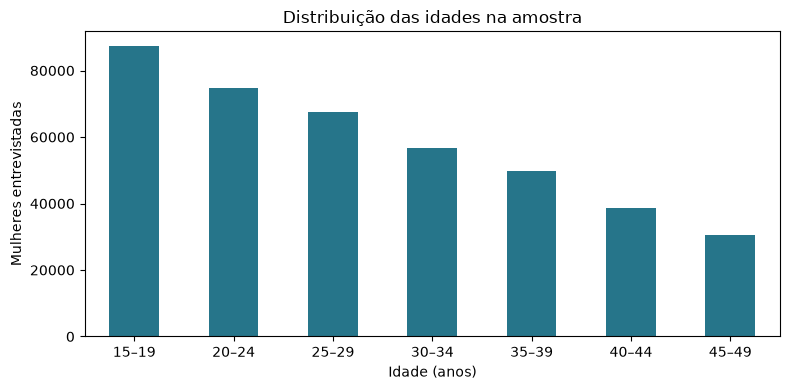

In [8]:
ax = idades.plot.bar(x='faixa_etaria', y='mulheres', legend=False,
                     color='#26758a', figsize=(8, 4), rot=0)
ax.set(title='Distribuição das idades na amostra',
       xlabel='Idade (anos)', ylabel='Mulheres entrevistadas')
plt.tight_layout()
plt.show()
plt.close()

### Como se distribui a escolaridade?

Mantemos as respostas ausentes em uma categoria separada para mostrar o tamanho dessa lacuna.

In [9]:
escolaridade = consulta("""
SELECT CASE escolaridade WHEN 0 THEN 'Sem escolaridade'
                         WHEN 1 THEN 'Primária'
                         WHEN 2 THEN 'Secundária'
                         WHEN 3 THEN 'Superior'
                         ELSE 'Sem informação' END AS escolaridade,
       COUNT(*) AS mulheres,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM Mulher), 2) AS percentual
FROM Mulher
GROUP BY escolaridade
ORDER BY MIN(COALESCE(Mulher.escolaridade, 9))
""")
display(escolaridade)

,escolaridade,mulheres,percentual
0,Sem escolaridade,119729,29.37
1,Primária,121895,29.91
2,Secundária,146903,36.04
3,Superior,19058,4.68
4,Sem informação,15,0.00


## 5. Análises bivariadas

**O uso de contraceptivos varia conforme a escolaridade e a residência?**

As duas consultas comparam grupos **dentro de cada levantamento**. `AVG(usa_contraceptivo)`
é a proporção de respostas 1 entre as respostas válidas (0 ou 1); os `NULL` ficam fora do denominador.
Mostramos também quantas mulheres ficaram sem resposta.

Os percentuais descrevem os registros da amostra, **sem pesos amostrais**. Não são estimativas populacionais.
As pesquisas podem ser de épocas diferentes, e associações observadas não demonstram causalidade.

In [10]:
uso_escolaridade = consulta("""
SELECT p.nome AS pais, l.id AS levantamento, m.escolaridade,
       COUNT(*) AS mulheres,
       COUNT(m.usa_contraceptivo) AS respostas_validas,
       COUNT(*) - COUNT(m.usa_contraceptivo) AS sem_resposta,
       ROUND(100.0 * AVG(m.usa_contraceptivo), 2) AS uso_pct
FROM Mulher m
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
WHERE m.escolaridade IS NOT NULL
GROUP BY p.codigo, p.nome, l.id, m.escolaridade
ORDER BY p.nome, l.id, m.escolaridade
""")
display(uso_escolaridade.head(12))
print(f'{len(uso_escolaridade)} grupos; resultado completo em uso_escolaridade.')

,pais,levantamento,escolaridade,mulheres,respostas_validas,sem_resposta,uso_pct
0,Angola,AO_81,0,3226,3226,0,5.05
1,Angola,AO_81,1,4149,4149,0,10.00
2,Angola,AO_81,2,6747,6747,0,20.71
3,Angola,AO_81,3,595,595,0,31.09
4,Benin,BJ_71,0,8762,8762,0,12.47
5,Benin,BJ_71,1,3116,3116,0,14.57
6,Benin,BJ_71,2,3685,3685,0,17.77
7,Benin,BJ_71,3,365,365,0,31.51
8,Burkina Faso,BF_81,0,10254,10254,0,29.78
9,Burkina Faso,BF_81,1,2515,2515,0,32.37


148 grupos; resultado completo em uso_escolaridade.


In [11]:
uso_residencia = consulta("""
SELECT p.nome AS pais, l.id AS levantamento,
       CASE d.residencia WHEN 1 THEN 'Urbana' WHEN 2 THEN 'Rural' END AS residencia,
       COUNT(*) AS mulheres,
       COUNT(m.usa_contraceptivo) AS respostas_validas,
       COUNT(*) - COUNT(m.usa_contraceptivo) AS sem_resposta,
       ROUND(100.0 * AVG(m.usa_contraceptivo), 2) AS uso_pct
FROM Mulher m
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
WHERE d.residencia IS NOT NULL
GROUP BY p.codigo, p.nome, l.id, d.residencia
ORDER BY p.nome, l.id, d.residencia
""")
display(uso_residencia.head(12))
print(f'{len(uso_residencia)} grupos; resultado completo em uso_residencia.')

,pais,levantamento,residencia,mulheres,respostas_validas,sem_resposta,uso_pct
0,Angola,AO_81,Urbana,9066,9066,0,19.24
1,Angola,AO_81,Rural,5651,5651,0,7.36
2,Benin,BJ_71,Urbana,7045,7045,0,16.93
3,Benin,BJ_71,Rural,8883,8883,0,12.65
4,Burkina Faso,BF_81,Urbana,6227,6227,0,35.88
5,Burkina Faso,BF_81,Rural,11432,11432,0,28.49
6,Burundi,BU_71,Urbana,3671,3671,0,20.65
7,Burundi,BU_71,Rural,13598,13598,0,16.60
8,Camarões,CM_82,Urbana,3755,0,3755,NaN
9,Camarões,CM_82,Rural,2777,0,2777,NaN


72 grupos; resultado completo em uso_residencia.


Para visualizar as comparações, escolhemos o levantamento com mais respostas válidas sobre contracepção.
Os gráficos usam a mesma escala de 0 a 100%. As tabelas anteriores contêm os demais levantamentos.

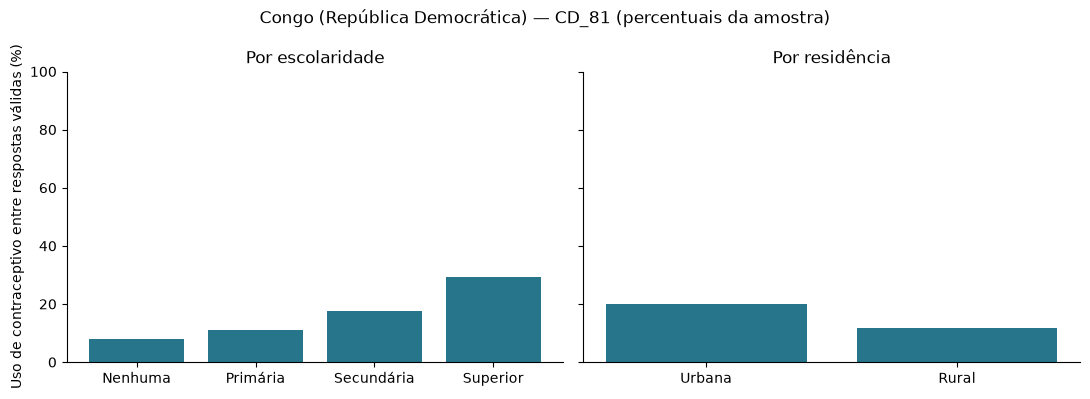

In [12]:
exemplo = cobertura.sort_values('respostas_contracepcao', ascending=False).iloc[0]
escola = uso_escolaridade[uso_escolaridade.levantamento == exemplo.levantamento].copy()
escola['grupo'] = escola.escolaridade.map({0: 'Nenhuma', 1: 'Primária', 2: 'Secundária', 3: 'Superior'})
residencia = uso_residencia[uso_residencia.levantamento == exemplo.levantamento]

fig, eixos = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, tabela, coluna, titulo in [(eixos[0], escola, 'grupo', 'Por escolaridade'),
                                  (eixos[1], residencia, 'residencia', 'Por residência')]:
    ax.bar(tabela[coluna], tabela.uso_pct, color='#26758a')
    ax.set(title=titulo, ylim=(0, 100), xlabel='')
    ax.spines[['top', 'right']].set_visible(False)
eixos[0].set_ylabel('Uso de contraceptivo entre respostas válidas (%)')
fig.suptitle(f'{exemplo.pais} — {exemplo.levantamento} (percentuais da amostra)')
fig.tight_layout()
plt.show()
plt.close(fig)

## 6. O que encontramos?

O resumo abaixo é calculado a partir das consultas, para acompanhar qualquer atualização dos dados.

In [13]:
total = int(cobertura.mulheres.sum())
sem_uso = int(ausentes.loc[ausentes.variavel == 'Uso de contraceptivo', 'ausentes'].iloc[0])
maior_faixa = idades.loc[idades.mulheres.idxmax(), 'faixa_etaria']
ur = residencia.set_index('residencia')['uso_pct']
display(Markdown(
    f'- O recorte reúne **{total:,} mulheres**, em **{len(cobertura)} levantamentos**.\n'
    f'- A faixa etária mais frequente é **{maior_faixa} anos**.\n'
    f'- **{sem_uso:,} entrevistas ({100 * sem_uso / total:.1f}%)** não têm informação válida sobre contracepção.\n'
    f'- Em **{exemplo.pais}**, o uso foi **{ur["Urbana"]:.1f}%** na área urbana e '
    f'**{ur["Rural"]:.1f}%** na rural, entre respostas válidas.\n\n'
    'A ausência de dados limita as comparações. Escolaridade, residência e contracepção podem estar '
    'associadas a outros fatores; este exercício descreve a amostra e não identifica causas.'
))

- O recorte reúne **407,600 mulheres**, em **37 levantamentos**.
- A faixa etária mais frequente é **15–19 anos**.
- **75,498 entrevistas (18.5%)** não têm informação válida sobre contracepção.
- Em **Congo (República Democrática)**, o uso foi **20.0%** na área urbana e **11.8%** na rural, entre respostas válidas.

A ausência de dados limita as comparações. Escolaridade, residência e contracepção podem estar associadas a outros fatores; este exercício descreve a amostra e não identifica causas.

### Conferência final

Verificamos se todas as entrevistas foram carregadas, se as ligações são válidas e se o arquivo SQLite está íntegro.
O banco fica salvo em `output/ibd012/saude_mulher_eda.db` e pode ser aberto em outro cliente SQLite.

In [14]:
assert conn.execute('SELECT COUNT(*) FROM Mulher').fetchone()[0] == esperado
assert cobertura.mulheres.sum() == esperado
assert conn.execute('PRAGMA foreign_keys').fetchone()[0] == 1
assert conn.execute('PRAGMA foreign_key_check').fetchall() == []
assert conn.execute('PRAGMA integrity_check').fetchone()[0] == 'ok'
conn.execute('DROP TABLE temp.Fonte')
conn.close()
print('Carga completa e relacionamentos conferidos.')
print(f'Banco salvo em: {banco}')

Carga completa e relacionamentos conferidos.
Banco salvo em: D:\Repositórios\África Subsaariana\output\ibd012\saude_mulher_eda.db
